# S4 — Phase 2 : segmentation et anomalies sur la BVMT

Projet Math en assurance et finance · 5INFINI · données du 02/01/2023 au 03/11/2026.

**Objectif.** Regrouper les titres qui se ressemblent (k-means) et repérer ceux qui ne ressemblent à aucun autre (Isolation Forest), à partir des 7 features calculées en S3. On travaille dans trois espaces :

| Espace | Variables | Pourquoi |
|---|---|---|
| **RV** | rendement et volatilité standardisés | le plan de l'article de référence, lisible directement |
| **7F** | les 7 features standardisées | toute l'information, mais avec des features redondantes (vol., VaR, CVaR) |
| **ACP** | les composantes principales qui expliquent ≥ 80 % de la variance | mêmes informations, décorrélées et débruitées |

**Entrées** (lecture seule, rien n'est modifié) :
- `data/s3/features_titres.csv` : 75 titres × 7 features (sortie de la S3) ;
- `data/processed/qualite_par_titre.csv` : nom, liquidité et statut de chaque titre (sortie de la S2).

**Sorties** : `data/processed/s4/` (CSV et graphiques), liste en section 11.

**Plan.**
0. Chargement et contrôles
1. Standardisation
2. ACP
3. k-means : choix de k
4. k-means : modèles retenus
5. Isolation Forest
6. Comparaison IF / k-means
7. Interprétation des clusters
8. Nature des anomalies
9. Titres liquides seulement
10. Secteurs
11. Synthèse et fichiers

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

GRAINE = 42                       # graine aléatoire fixe (k-means, Isolation Forest)
K_PLAGE = range(3, 9)             # k testés : 3 à 8
TAUX_IF = [0.03, 0.05, 0.08, 0.10]
TAUX_RETENU = 0.05                # justifié en section 5
SEUIL_LIQUIDITE = 0.60            # même seuil qu'en S2

RACINE = Path("..")               # le notebook est dans notebooks/
F_PATH = RACINE / "data" / "s3" / "features_titres.csv"
Q_PATH = RACINE / "data" / "processed" / "qualite_par_titre.csv"
OUT = RACINE / "data" / "processed" / "s4"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 170, "display.max_columns", 20, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 0. Chargement et contrôles

On lit les colonnes réellement présentes avant de les utiliser.

- **`features_titres.csv`** : une ligne par titre (`ticker`) et 7 colonnes de features.
- **`qualite_par_titre.csv`** : 85 sociétés, dont les 10 qui ne sont plus cotées.

Les colonnes utilisées dans `qualite_par_titre.csv` :
- `nom` ;
- `part_seances_echangees` : part des séances avec au moins une transaction ;
- `part_rendements_nuls` ;
- `retenu` : True si la société a été échangée au moins 60 % des séances.

In [2]:
F_brut = pd.read_csv(F_PATH)
Q_brut = pd.read_csv(Q_PATH)
print("features_titres.csv :", F_brut.shape, list(F_brut.columns))
print("qualite_par_titre.csv :", Q_brut.shape, list(Q_brut.columns))

F = F_brut.set_index("ticker")
FEATURES = list(F.columns)
Q = Q_brut.dropna(subset=["ticker"]).set_index("ticker").loc[F.index]
info = Q[["nom", "part_seances_echangees", "part_rendements_nuls", "retenu"]].copy()
info["liquide"] = info["retenu"].astype(bool)

assert F.shape == (75, 7) and F.notna().all().all(), "features : 75 × 7 sans manquant attendu"
assert (info.liquide == (info.part_seances_echangees >= SEUIL_LIQUIDITE)).all()
print(f"\n{len(F)} titres, dont {info.liquide.sum()} liquides et {(~info.liquide).sum()} peu liquides (< 60 % de séances échangées)")
F.describe().T[["mean", "std", "min", "50%", "max"]]

features_titres.csv : (75, 8) ['ticker', 'rendement_annualise', 'volatilite_annualisee', 'skewness', 'kurtosis', 'var_95', 'cvar_95', 'beta']
qualite_par_titre.csv : (85, 14) ['ticker', 'nom', 'isin', 'groupe', 'premiere_seance', 'derniere_seance', 'nb_lignes', 'seances_manquantes', 'part_seances_echangees', 'part_rendements_nuls', 'capitaux_median_2023_2025', 'nb_ost', 'retenu', 'motif_exclusion']

75 titres, dont 57 liquides et 18 peu liquides (< 60 % de séances échangées)


,mean,std,min,50%,max
rendement_annualise,0.153,0.201,-0.391,0.172,5.944e-01
volatilite_annualisee,0.260,0.077,0.048,0.243,4.120e-01
skewness,0.471,1.377,-0.777,0.263,1.173e+01
kurtosis,6.043,20.204,-0.947,2.834,1.643e+02
var_95,-0.026,0.012,-0.045,-0.024,0.000e+00
cvar_95,-0.035,0.011,-0.051,-0.038,-4.118e-05
beta,0.432,0.390,-0.190,0.395,1.556e+00


**À noter avant de standardiser.** Les distributions sont très asymétriques : le kurtosis va de −0,9 à 164 (PLTU). Un titre aussi extrême pèsera lourd dans toute méthode fondée sur des distances. C'est voulu ici, puisqu'on cherche justement les titres atypiques, mais il faudra en tenir compte dans l'interprétation.

## 1. Standardisation

Chaque feature est centrée et réduite : z = (x − moyenne) / écart-type, calculés sur les 75 titres.

Sans cette étape, une feature exprimée en grands nombres (le kurtosis, jusqu'à 164) écraserait celles qui varient sur quelques centièmes (VaR, CVaR) dans le calcul des distances de k-means et d'Isolation Forest.

In [3]:
def standardiser(F):
    return pd.DataFrame(StandardScaler().fit_transform(F), index=F.index, columns=F.columns)

Z = standardiser(F)
print("moyennes ≈ 0 :", np.allclose(Z.mean(), 0), "| écarts-types = 1 (ddof=0) :", np.allclose(Z.std(ddof=0), 1))
print("\nTitres avec au moins une feature à |z| > 3 :")
ext = (Z.abs() > 3)
print(pd.DataFrame({"features extrêmes": ext.apply(lambda r: ", ".join(Z.columns[r]), axis=1)})[ext.any(axis=1)].join(info[["part_seances_echangees"]]))

moyennes ≈ 0 : True | écarts-types = 1 (ddof=0) : True

Titres avec au moins une feature à |z| > 3 :
                  features extrêmes  part_seances_echangees
ticker                                                     
SIMPA             kurtosis, cvar_95                   0.118
BHASS                       cvar_95                   0.096
PLTU    skewness, kurtosis, cvar_95                   0.040


## 2. Analyse en composantes principales (ACP)

L'ACP remplace les 7 features corrélées par des composantes non corrélées, classées par part de variance expliquée. On garde le plus petit nombre de composantes qui atteint **80 %** de la variance cumulée.

In [4]:
def acp(Z, seuil=0.80):
    p = PCA(random_state=GRAINE).fit(Z)
    var = pd.DataFrame({"variance_expliquee": p.explained_variance_ratio_,
                        "variance_cumulee": p.explained_variance_ratio_.cumsum()},
                       index=[f"PC{i+1}" for i in range(Z.shape[1])])
    n80 = int(np.argmax(var.variance_cumulee.values >= seuil) + 1)
    charges = pd.DataFrame(p.components_.T, index=Z.columns, columns=var.index)
    scores = pd.DataFrame(p.transform(Z), index=Z.index, columns=var.index)
    return var, n80, charges, scores

var75, N80, charges75, pcs75 = acp(Z)
var75.to_csv(OUT / "acp_variance.csv")
charges75.iloc[:, :3].to_csv(OUT / "acp_charges_3pc.csv")
print(f"Composantes pour atteindre 80 % de variance : {N80}")
print(var75.round(3).T)
print("\nCharges des 3 premières composantes :")
charges75.iloc[:, :3].round(2)

Composantes pour atteindre 80 % de variance : 3
                      PC1    PC2    PC3    PC4    PC5    PC6    PC7
variance_expliquee  0.545  0.239  0.105  0.074  0.021  0.009  0.007
variance_cumulee    0.545  0.784  0.889  0.963  0.984  0.993  1.000

Charges des 3 premières composantes :


,PC1,PC2,PC3
rendement_annualise,0.17,0.49,0.71
volatilite_annualisee,-0.46,-0.08,0.33
skewness,0.38,-0.39,0.42
kurtosis,0.36,-0.49,0.27
var_95,0.47,0.18,-0.26
cvar_95,0.47,0.03,-0.24
beta,0.19,0.57,0.04


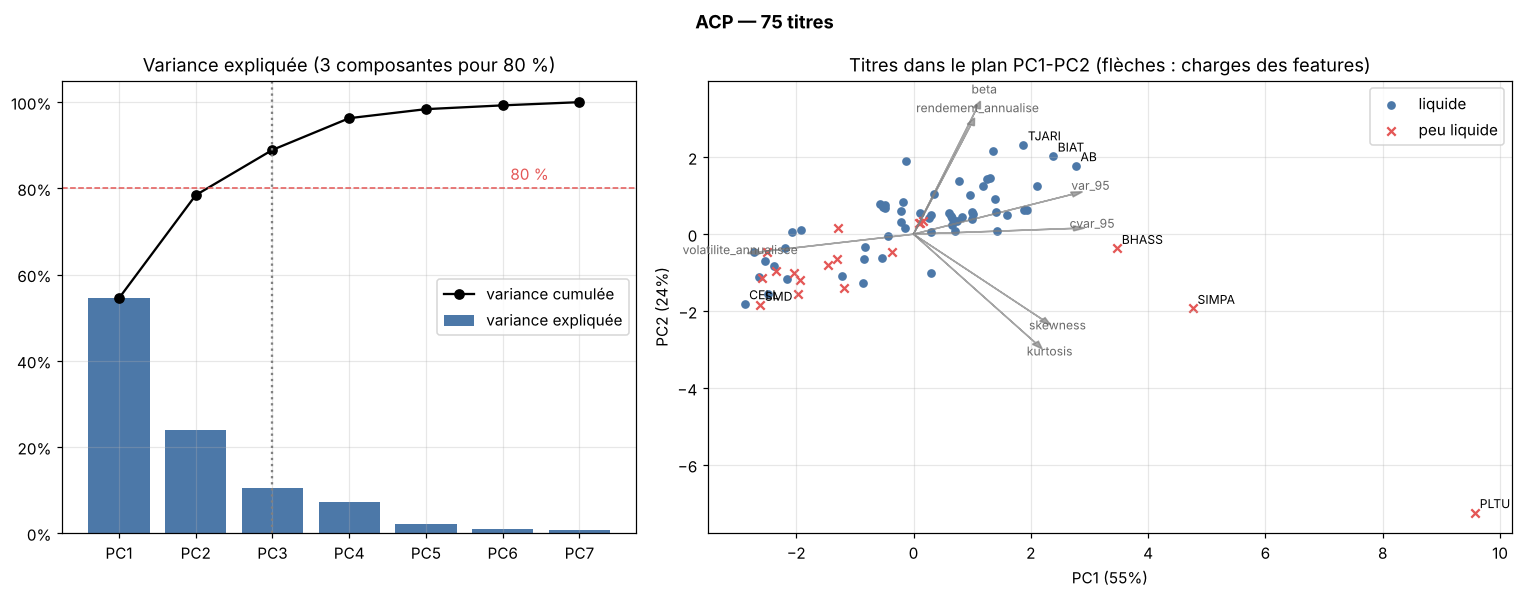

In [5]:
def graph_acp(var, n80, charges, scores, info, titre, fichier):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
    x = np.arange(1, len(var) + 1)
    ax[0].bar(x, var.variance_expliquee, color="#4C78A8", label="variance expliquée")
    ax[0].plot(x, var.variance_cumulee, "o-", c="black", label="variance cumulée")
    ax[0].axhline(0.8, ls="--", c="#E45756", lw=1); ax[0].text(len(var) - 0.4, 0.82, "80 %", color="#E45756", ha="right")
    ax[0].axvline(n80, ls=":", c="gray"); ax[0].set_xticks(x); ax[0].set_xticklabels(var.index)
    ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax[0].set_title(f"Variance expliquée ({n80} composantes pour 80 %)"); ax[0].legend(loc="center right")
    liq = info.liquide.reindex(scores.index)
    ax[1].scatter(scores.PC1[liq], scores.PC2[liq], s=22, c="#4C78A8", label="liquide")
    ax[1].scatter(scores.PC1[~liq], scores.PC2[~liq], s=30, c="#E45756", marker="x", label="peu liquide")
    lim = np.abs(scores[["PC1", "PC2"]]).max().max()
    for f, (a, b) in charges[["PC1", "PC2"]].iterrows():
        ax[1].arrow(0, 0, a * lim * 0.6, b * lim * 0.6, color="gray", alpha=0.7, head_width=0.08 * lim / 6)
        ax[1].text(a * lim * 0.67, b * lim * 0.67, f, fontsize=8, color="dimgray", ha="center")
    loin = (scores.PC1 ** 2 + scores.PC2 ** 2).sort_values(ascending=False).index[:8]
    for t in loin:
        ax[1].annotate(t, (scores.PC1[t], scores.PC2[t]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax[1].set_xlabel(f"PC1 ({var.variance_expliquee.iloc[0]:.0%})"); ax[1].set_ylabel(f"PC2 ({var.variance_expliquee.iloc[1]:.0%})")
    ax[1].set_title("Titres dans le plan PC1-PC2 (flèches : charges des features)"); ax[1].legend()
    fig.suptitle(titre, fontweight="bold"); fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_acp(var75, N80, charges75, pcs75, info, "ACP — 75 titres", "s4_acp.png")

**Lecture de l'ACP (75 titres).**
- **3 composantes** suffisent pour dépasser 80 % de la variance. PC1 en explique à elle seule environ 55 %.
- **PC1 est un axe « risque »** : la VaR et la CVaR (négatives, donc plus grandes quand le risque est faible) pèsent dans un sens, la volatilité dans l'autre. Les titres à droite sont peu risqués, ou plutôt *paraissent* peu risqués : skewness et kurtosis chargent aussi positivement, et c'est la signature des titres dont le prix bouge rarement mais par sauts.
- **PC2 est un axe « marché et rendement »** : il oppose le bêta et le rendement d'un côté au kurtosis et à la skewness de l'autre.
- **PC3 est surtout porté par le rendement.**
- Les titres peu liquides (croix rouges) s'étalent loin de la masse : PLTU, SIMPA et BHASS sont tirés par le kurtosis et la VaR nulle.

## 3. k-means : choix de k

On applique k-means (initialisation **k-means++**, 50 initialisations, graine 42) dans les trois espaces, pour k = 3 à 8. Quatre critères sont calculés pour chaque k :

| Critère | Ce qu'il mesure | Meilleur k |
|---|---|---|
| Coude | inertie intra-cluster ; on cherche le point où ajouter un cluster ne fait plus beaucoup baisser l'inertie | point de courbure maximale (méthode de la corde) |
| Silhouette | ressemblance d'un titre à son cluster comparée au cluster voisin, entre −1 et 1 | le plus élevé |
| Calinski-Harabasz (CH) | dispersion entre clusters / dispersion dans les clusters | le plus élevé |
| Davies-Bouldin (DB) | ressemblance moyenne de chaque cluster à son plus proche voisin | le plus bas |

**Règle de choix, appliquée identiquement partout.** Chaque critère vote pour un k ; on retient le k qui recueille le plus de votes, donc soutenu par **au moins deux critères**. En cas d'égalité, la silhouette tranche. On **signale** :
- tout k retenu au bord de la plage (3 ou 8) : le vrai optimum pourrait être en dehors ;
- tout cluster d'un seul titre ;
- toute silhouette < 0,5, qui indique une structure de groupes faible.

In [6]:
def coude(ks, inerties):
    """k de courbure maximale : point le plus éloigné, sous la corde, de la courbe d'inertie normalisée."""
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.array(inerties) - min(inerties)) / (max(inerties) - min(inerties))
    return ks[int(np.argmax((1 - x) - y))]

def espaces(Z, n80):
    p = PCA(n_components=n80, random_state=GRAINE).fit(Z)
    return {"RV": pd.DataFrame(Z[["rendement_annualise", "volatilite_annualisee"]].values, index=Z.index, columns=["z_rendement", "z_volatilite"]),
            "7F": Z.copy(),
            "ACP": pd.DataFrame(p.transform(Z), index=Z.index, columns=[f"PC{i+1}" for i in range(n80)])}

def kmeans(X, k):
    return KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=GRAINE).fit(X)

def choix_k(X):
    lignes = []
    for k in K_PLAGE:
        km = kmeans(X, k); tailles = np.bincount(km.labels_)
        lignes.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                       "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
                       "davies_bouldin": davies_bouldin_score(X, km.labels_),
                       "tailles": " / ".join(map(str, sorted(tailles, reverse=True))), "nb_singletons": int((tailles == 1).sum())})
    t = pd.DataFrame(lignes).set_index("k")
    ks = list(t.index)
    votes = {"coude": coude(ks, t.inertie.tolist()), "silhouette": int(t.silhouette.idxmax()),
             "calinski_harabasz": int(t.calinski_harabasz.idxmax()), "davies_bouldin": int(t.davies_bouldin.idxmin())}
    compte = pd.Series(list(votes.values())).value_counts()
    meilleurs = compte[compte == compte.max()].index.tolist()
    k_ret = int(max(meilleurs, key=lambda k: t.silhouette[k]))
    return t, votes, k_ret

def rapport_k(nom, t, votes, k):
    soutiens = [c for c, v in votes.items() if v == k]
    alertes = []
    if k in (min(K_PLAGE), max(K_PLAGE)): alertes.append(f"k = {k} AU BORD de la plage {min(K_PLAGE)}-{max(K_PLAGE)}")
    if t.nb_singletons[k] > 0: alertes.append(f"{t.nb_singletons[k]} cluster(s) d'un seul titre")
    if t.silhouette[k] < 0.5: alertes.append(f"silhouette {t.silhouette[k]:.2f} < 0,5 : structure faible")
    print(f"{nom:4s} votes {votes} → k retenu = {k} (soutenu par : {', '.join(soutiens)})")
    for a in alertes: print("      ⚠", a)
    return {"espace": nom, "k_retenu": k, "criteres_en_faveur": ", ".join(soutiens), **{f"vote_{c}": v for c, v in votes.items()},
            "silhouette": round(t.silhouette[k], 3), "tailles": t.tailles[k], "alertes": " ; ".join(alertes)}

ESP75 = espaces(Z, N80)
CHOIX75, TABK75, K75 = [], {}, {}
for nom, X in ESP75.items():
    t, votes, k = choix_k(X); TABK75[nom] = t; K75[nom] = k
    CHOIX75.append(rapport_k(nom, t, votes, k))
pd.concat({n: t for n, t in TABK75.items()}, names=["espace"]).to_csv(OUT / "choix_k_criteres.csv")
pd.DataFrame(CHOIX75).to_csv(OUT / "choix_k_retenus.csv", index=False)
pd.concat({n: t[["silhouette", "calinski_harabasz", "davies_bouldin", "tailles"]] for n, t in TABK75.items()}, axis=1).round(3)

RV   votes {'coude': 5, 'silhouette': 8, 'calinski_harabasz': 8, 'davies_bouldin': 8} → k retenu = 8 (soutenu par : silhouette, calinski_harabasz, davies_bouldin)
      ⚠ k = 8 AU BORD de la plage 3-8
      ⚠ silhouette 0.44 < 0,5 : structure faible
7F   votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 3} → k retenu = 3 (soutenu par : silhouette, calinski_harabasz, davies_bouldin)
      ⚠ k = 3 AU BORD de la plage 3-8
      ⚠ 1 cluster(s) d'un seul titre
      ⚠ silhouette 0.41 < 0,5 : structure faible


ACP  votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 8, 'davies_bouldin': 3} → k retenu = 3 (soutenu par : silhouette, davies_bouldin)
      ⚠ k = 3 AU BORD de la plage 3-8
      ⚠ 1 cluster(s) d'un seul titre
      ⚠ silhouette 0.47 < 0,5 : structure faible


RV                                                                            7F                                                                      \
  silhouette calinski_harabasz davies_bouldin                           tailles silhouette calinski_harabasz davies_bouldin                            tailles   
k                                                                                                                                                                
3      0.407            57.181          0.820                      37 / 26 / 12      0.406            56.978          0.657                        48 / 26 / 1   
4      0.421            59.844          0.839                 37 / 17 / 11 / 10      0.314            54.899          0.904                   33 / 25 / 16 / 1   
5      0.383            62.765          0.802            26 / 17 / 11 / 11 / 10      0.309            54.459          0.829               30 / 25 / 17 / 2 / 1   
6      0.401            65.790          0.734        22 / 13 / 11 / 11 / 10 / 8      0.288            53.892          0.912          29 / 16 / 16 / 11 / 2 / 1   
7      0.413            69.530          0.667     21 / 15 / 11 / 10 / 8 / 7 / 3      0.274            51.563          0.922      25 / 16 / 15 / 10 / 6 / 2 / 1   
8      0.441            72.581          0.626  22 / 13 / 11 / 9 / 8 / 7 / 3 / 2      0.283            51.417          0.902  21 / 16 / 12 / 10 / 7 / 6 / 2 / 1   

         ACP                                                                     
  silhouette calinski_harabasz davies_bouldin                           tailles  
k                                                                                
3      0.469            77.406          0.550                       47 / 27 / 1  
4      0.412            78.114          0.730                  38 / 26 / 10 / 1  
5      0.370            78.373          0.702              32 / 23 / 17 / 2 / 1  
6      0.367            85.191          0.750          28 / 18 / 17 / 9 / 2 / 1  
7      0.373            88.261          0.708      27 / 17 / 14 / 8 / 6 / 2 / 1  
8      0.382            92.859          0.694  23 / 16 / 14 / 8 / 6 / 5 / 2 / 1

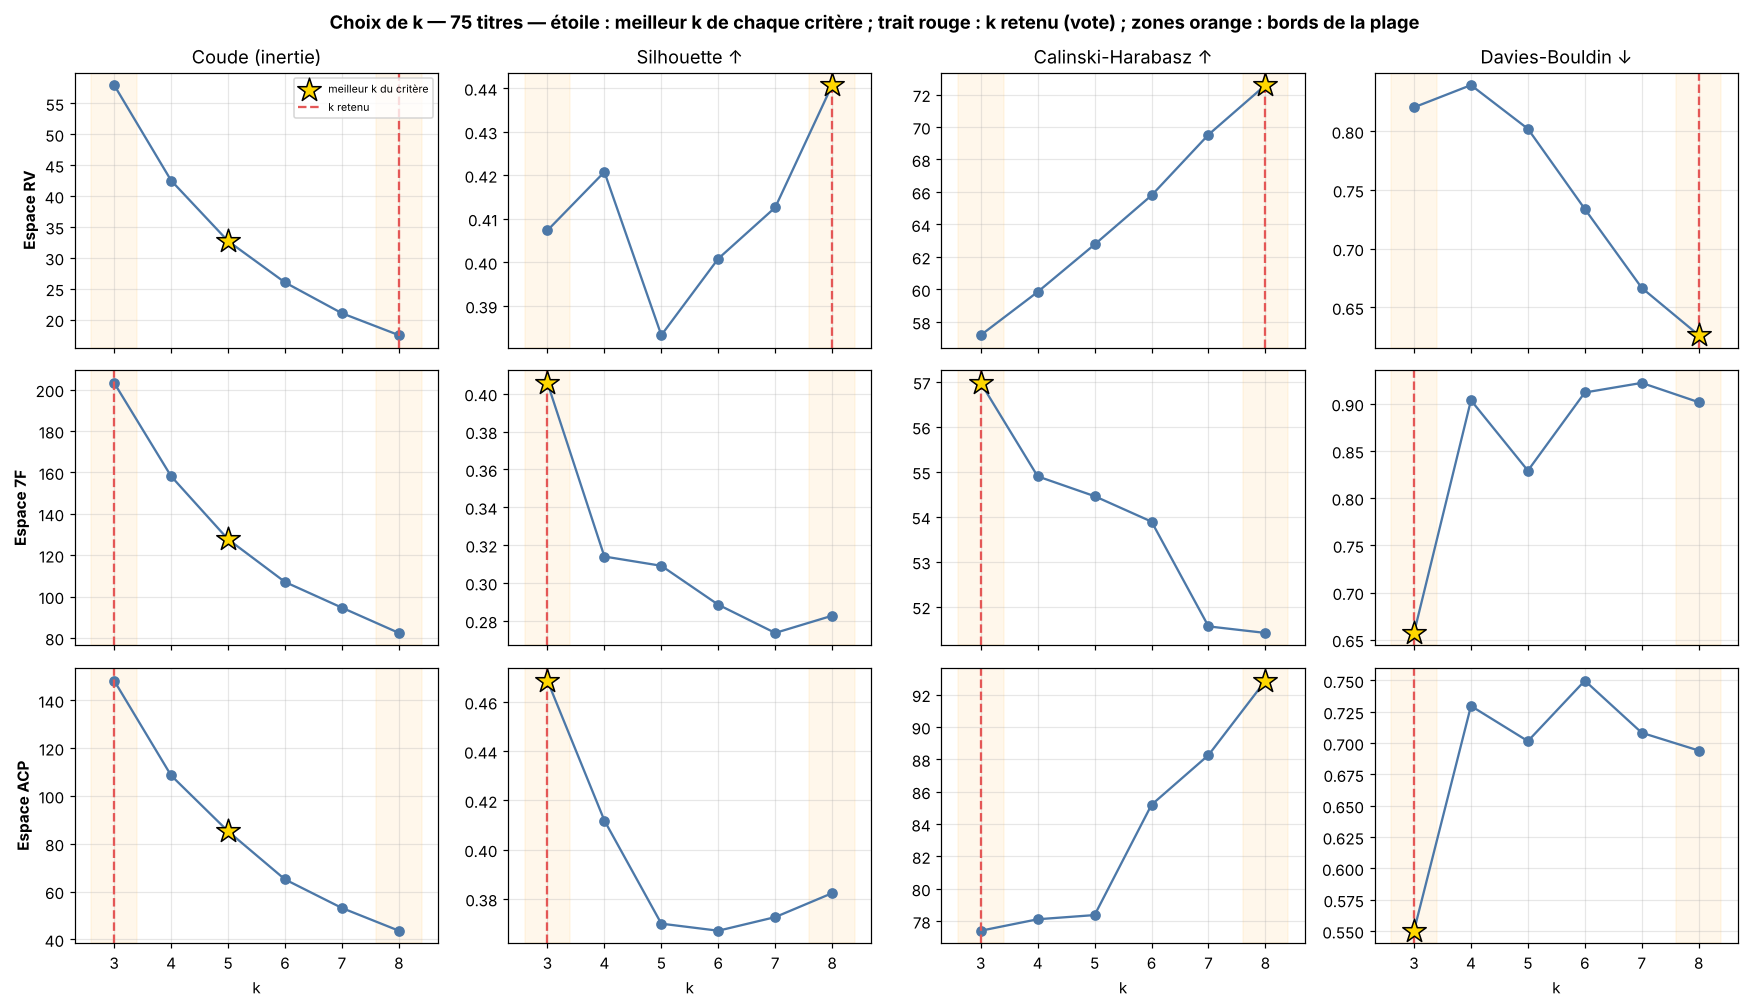

In [7]:
def graph_k(tabs, kret, titre, fichier):
    crit = [("inertie", "Coude (inertie)", None), ("silhouette", "Silhouette ↑", "max"),
            ("calinski_harabasz", "Calinski-Harabasz ↑", "max"), ("davies_bouldin", "Davies-Bouldin ↓", "min")]
    fig, ax = plt.subplots(len(tabs), 4, figsize=(16, 3.1 * len(tabs)), sharex=True)
    for i, (nom, t) in enumerate(tabs.items()):
        for j, (c, lab, sens) in enumerate(crit):
            a = ax[i, j]; a.plot(t.index, t[c], "o-", c="#4C78A8")
            vote = coude(list(t.index), t.inertie.tolist()) if sens is None else (t[c].idxmax() if sens == "max" else t[c].idxmin())
            a.scatter([vote], [t.loc[vote, c]], marker="*", s=260, c="gold", ec="k", zorder=6, label="meilleur k du critère")
            a.axvline(kret[nom], c="#E45756", ls="--", lw=1.5, label="k retenu")
            if i == 0 and j == 0: a.legend(fontsize=7, loc="upper right")
            a.axvspan(2.6, 3.4, color="orange", alpha=0.08); a.axvspan(7.6, 8.4, color="orange", alpha=0.08)
            if i == 0: a.set_title(lab)
            if j == 0: a.set_ylabel(f"Espace {nom}", fontweight="bold")
            if i == len(tabs) - 1: a.set_xlabel("k")
    fig.suptitle(titre + " — étoile : meilleur k de chaque critère ; trait rouge : k retenu (vote) ; zones orange : bords de la plage", fontweight="bold")
    fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_k(TABK75, K75, "Choix de k — 75 titres", "s4_choix_k.png")

**Lecture du choix de k (75 titres).**
- **Espace RV** : silhouette, CH et DB s'améliorent tous jusqu'à k = 8, et k = 8 est donc retenu, **au bord de la plage**. Ces critères continuent de progresser parce que le plan rendement-volatilité forme un nuage continu, sans groupes naturels : plus on découpe, plus les morceaux sont compacts. Le coude (k = 5) est le seul critère qui suggère un nombre plus modeste.
- **Espaces 7F et ACP** : k = 3 est retenu, **au bord de la plage**, et l'un des 3 clusters est **un singleton : PLTU**. Ce singleton est là quel que soit k (voir la colonne `nb_singletons` de `choix_k_criteres.csv`). Ce n'est donc pas un groupe financier, mais un titre si extrême qu'il forme son propre cluster. Avec k = 3, le partage réel n'oppose que deux groupes.
- **Les silhouettes restent faibles partout** (0,41 à 0,47 au k retenu) : les « groupes » de la BVMT sont peu séparés. C'est une limite à affirmer clairement, car l'article ne la mesure pas.

## 4. k-means : modèles retenus

In [8]:
def ajuster(espaces, kret):
    lab = {}
    for nom, X in espaces.items():
        km = kmeans(X, kret[nom])
        # numérotation stable : cluster 1 = le plus grand, etc.
        ordre = pd.Series(km.labels_).value_counts().index
        lab[nom] = pd.Series(pd.Series(km.labels_).map({c: i + 1 for i, c in enumerate(ordre)}).values, index=X.index)
    return pd.DataFrame(lab).add_prefix("cluster_")

CL75 = ajuster(ESP75, K75)
for c in CL75:
    tailles = CL75[c].value_counts().sort_index()
    print(f"{c:12s} tailles : {dict(tailles)}  | singletons : {[CL75.index[CL75[c] == k][0] for k in tailles.index[tailles == 1]]}")

cluster_RV   tailles : {1: np.int64(22), 2: np.int64(13), 3: np.int64(11), 4: np.int64(9), 5: np.int64(8), 6: np.int64(7), 7: np.int64(3), 8: np.int64(2)}  | singletons : []
cluster_7F   tailles : {1: np.int64(48), 2: np.int64(26), 3: np.int64(1)}  | singletons : ['PLTU']
cluster_ACP  tailles : {1: np.int64(47), 2: np.int64(27), 3: np.int64(1)}  | singletons : ['PLTU']


## 5. Isolation Forest

Isolation Forest construit des arbres de découpes aléatoires : un titre **anormal s'isole en peu de découpes**. On utilise 500 arbres et la graine 42, dans les trois mêmes espaces.

Le **score d'anomalie** (ici −`score_samples`, plus haut = plus anormal) ne dépend pas du taux de contamination. Le taux ne fait que fixer **le seuil** au-delà duquel un titre est signalé. On peut donc comparer les taux 3, 5, 8 et 10 % sur les mêmes scores.

**Choix du taux : 5 %**, soit 4 titres sur 75, pour trois raisons :
1. C'est le taux de l'article de référence, ce qui rend les résultats comparables.
2. Le tableau de stabilité ci-dessous montre qu'à 5 %, les titres signalés font presque tous partie du noyau signalé à tous les taux. À 8-10 %, des titres liquides au profil seulement un peu atypique apparaissent et varient d'un espace à l'autre.
3. Le graphique des scores triés montre une rupture après les 3 à 5 premiers titres dans chaque espace.

On appelle **anomalie stable** un titre signalé dans au moins 8 des 12 combinaisons (3 espaces × 4 taux).

In [9]:
def isolation(espaces):
    scores, sig = {}, {}
    for nom, X in espaces.items():
        f = IsolationForest(n_estimators=500, contamination="auto", random_state=GRAINE).fit(X)
        s = pd.Series(-f.score_samples(X), index=X.index)       # plus haut = plus anormal
        scores[nom] = s
        for taux in TAUX_IF:
            n = int(np.ceil(taux * len(s)))                      # nombre de titres signalés à ce taux
            sig[(nom, taux)] = s.index.isin(s.nlargest(n).index)
    S = pd.DataFrame(scores).add_prefix("score_if_")
    SIG = pd.DataFrame(sig, index=S.index)
    return S, SIG

SC75, SIG75 = isolation(ESP75)
# contrôle : notre seuil par rang donne les mêmes titres que IsolationForest(contamination=taux)
for nom, X in ESP75.items():
    for taux in TAUX_IF:
        f = IsolationForest(n_estimators=500, contamination=taux, random_state=GRAINE).fit(X)
        assert set(X.index[f.predict(X) == -1]) == set(SIG75.index[SIG75[(nom, taux)]]), (nom, taux)
print("Contrôle OK : identique à IsolationForest(contamination=taux) pour les 12 combinaisons")

def tableau_stabilite(SIG):
    lignes = []
    for (nom, taux), col in SIG.items():
        lignes.append({"espace": nom, "taux": f"{taux:.0%}", "nb_signales": int(col.sum()),
                       "titres_signales": ", ".join(sorted(SIG.index[col]))})
    return pd.DataFrame(lignes)

STAB75 = tableau_stabilite(SIG75)
NB75 = SIG75.sum(axis=1).rename("nb_signalements_sur_12")
STAB75.to_csv(OUT / "stabilite_isolation_forest.csv", index=False)
print(STAB75.to_string(index=False))
print("\nNombre de signalements par titre (sur 12), titres signalés au moins une fois :")
print(NB75[NB75 > 0].sort_values(ascending=False).to_frame().join(info[["part_seances_echangees", "liquide"]]).to_string())

Contrôle OK : identique à IsolationForest(contamination=taux) pour les 12 combinaisons
espace taux  nb_signales                                  titres_signales
    RV   3%            3                                 PLTU, SMD, SOTET
    RV   5%            4                          PLTU, SIMPA, SMD, SOTET
    RV   8%            6               AB, ALKIM, PLTU, SIMPA, SMD, SOTET
    RV  10%            8     AB, ALKIM, BHL, PLTU, SCB, SIMPA, SMD, SOTET
    7F   3%            3                               BHASS, PLTU, SIMPA
    7F   5%            4                           AB, BHASS, PLTU, SIMPA
    7F   8%            6             AB, ALKIM, BHASS, PLTU, SIMPA, SOTET
    7F  10%            8 AB, ALKIM, BHASS, BIAT, PLTU, SIMPA, SOTET, TAIR
   ACP   3%            3                               PLTU, SIMPA, SOTET
   ACP   5%            4                        BHASS, PLTU, SIMPA, SOTET
   ACP   8%            6           ALKIM, BHASS, CELL, PLTU, SIMPA, SOTET
   ACP  10%            8 

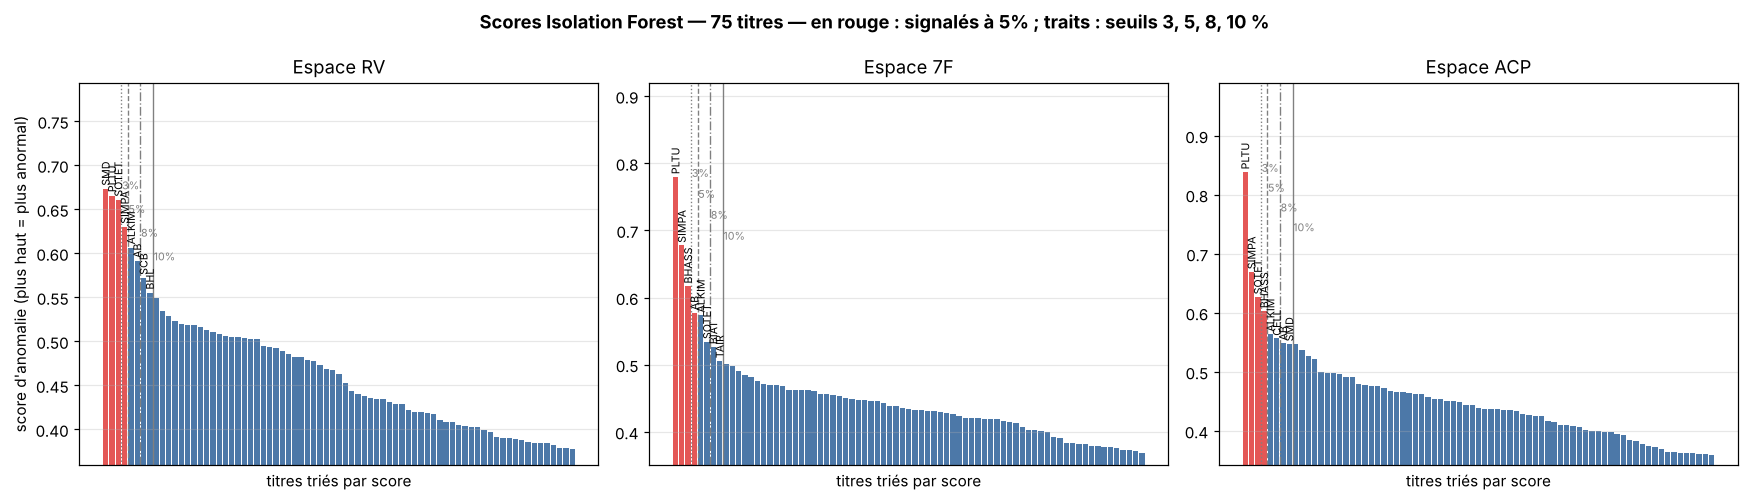

In [10]:
def graph_scores(SC, SIG, titre, fichier, n_lab=8):
    fig, ax = plt.subplots(1, len(SC.columns), figsize=(16, 4.6))
    for a, c in zip(ax, SC.columns):
        nom = c.replace("score_if_", ""); s = SC[c].sort_values(ascending=False)
        n5 = int(np.ceil(TAUX_RETENU * len(s)))
        couleurs = ["#E45756" if i < n5 else "#4C78A8" for i in range(len(s))]
        a.bar(range(len(s)), s.values, color=couleurs, width=0.85)
        for taux, ls in zip(TAUX_IF, [":", "--", "-.", "-"]):
            n = int(np.ceil(taux * len(s))); a.axvline(n - 0.5, ls=ls, c="gray", lw=0.9)
            a.text(n - 0.4, s.max() * (1.0 - 0.04 * TAUX_IF.index(taux)), f"{taux:.0%}", fontsize=7, color="gray")
        for i, t in enumerate(s.index[:n_lab]):
            a.text(i, s.iloc[i] + 0.004, t, rotation=90, fontsize=7, ha="center", va="bottom")
        a.set_ylim(s.min() * 0.95, s.max() * 1.18); a.set_title(f"Espace {nom}"); a.set_xlabel("titres triés par score")
        a.set_xticks([])
    ax[0].set_ylabel("score d'anomalie (plus haut = plus anormal)")
    fig.suptitle(titre + f" — en rouge : signalés à {TAUX_RETENU:.0%} ; traits : seuils 3, 5, 8, 10 %", fontweight="bold")
    fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_scores(SC75, SIG75, "Scores Isolation Forest — 75 titres", "s4_scores_isolation_forest.png")

**Lecture.**
- **PLTU et SIMPA** sont signalés dans toutes les combinaisons ou presque : ce sont les anomalies les plus stables.
- **SOTET et BHASS** viennent ensuite. AB (Amen Bank) apparaît dans une partie des combinaisons.
- **Trois anomalies stables** (au moins 8 signalements sur 12) : PLTU (12), SIMPA (11) et SOTET (10).
- Au-delà de 5 %, les titres ajoutés changent d'un espace à l'autre (ALKIM, CELL, BIAT, TAIR, BHL, SCB…). C'est le signe que le seuil devient arbitraire, et c'est pour cela qu'on retient 5 %.

## 6. Comparaison : anomalies Isolation Forest et titres isolés par k-means

**Définitions.**
- **Isolé par k-means** : titre appartenant à un cluster d'**au plus 2 titres** dans au moins un espace, au k retenu.
- **Signalé par IF** : titre signalé au taux retenu (5 %) dans au moins un espace.

On compare aussi avec les anomalies stables (au moins 8 signalements sur 12).

In [11]:
def comparaison(CL, SIG, NB):
    iso = set()
    for c in CL:
        t = CL[c].value_counts(); iso |= set(CL.index[CL[c].isin(t[t <= 2].index)])
    if_ = set(SIG.index[SIG.xs(TAUX_RETENU, level=1, axis=1).any(axis=1)])
    stables = set(NB.index[NB >= 8])
    lignes = [("en commun (IF et k-means)", sorted(if_ & iso)), ("seulement Isolation Forest", sorted(if_ - iso)),
              ("seulement k-means", sorted(iso - if_))]
    tab = pd.DataFrame([{"categorie": c, "nb": len(l), "titres": ", ".join(l)} for c, l in lignes])
    return tab, iso, if_, stables

COMP75, ISO75, IF75, STABLES75 = comparaison(CL75, SIG75, NB75)
COMP75.to_csv(OUT / "comparaison_if_kmeans.csv", index=False)
print(COMP75.to_string(index=False))
print("\nAnomalies stables (≥ 8/12) :", sorted(STABLES75))

                 categorie  nb                titres
 en commun (IF et k-means)   2           PLTU, SIMPA
seulement Isolation Forest   4 AB, BHASS, SMD, SOTET
         seulement k-means   0                      

Anomalies stables (≥ 8/12) : ['PLTU', 'SIMPA', 'SOTET']


**Lecture.** Les deux méthodes s'accordent sur le cœur : les titres qui forment un cluster minuscule dans k-means sont aussi ceux qu'Isolation Forest isole le plus vite. C'est attendu, puisque k-means et IF réagissent tous les deux aux points éloignés de la masse. Les titres signalés par une seule méthode sont des cas intermédiaires : IF les isole sans qu'ils soient assez loin pour former leur propre cluster, ou l'inverse.

## 7. Interprétation des clusters

Pour chaque cluster de chaque espace, on calcule :
- la taille et la liste des titres ;
- les **médianes** du rendement, de la volatilité, du bêta et de la liquidité (part de séances échangées). La médiane est préférée à la moyenne parce qu'un seul titre extrême fausse une moyenne ;
- le nombre de titres peu liquides et le nombre d'anomalies IF (taux 5 %, même espace).

**Nom financier court.** Il est attribué par une règle fixe, appliquée à tous les clusters, et non choisi à la main :
- Si la liquidité médiane du cluster est inférieure à 60 %, on le nomme « Peu liquides, prix figés ».
- Sinon, on compare son rendement et sa volatilité médians à ceux de l'univers :

| | Volatilité basse | Volatilité haute |
|---|---|---|
| **Rendement haut** | « Croissance régulière » | « Forte hausse, volatiles » |
| **Rendement bas** | « Défensives, rendement faible » | « Volatiles, rendement faible » |

- Un rendement médian négatif ajoute « (en baisse) ». Un bêta médian ≥ 1,2 ajoute « , sensibles au marché » ; un bêta ≤ 0,3 ajoute « , peu liés au marché ».

Aucun secteur n'est utilisé (voir section 10).

In [12]:
def nommer(r, ref):
    if r.liquidite_mediane < SEUIL_LIQUIDITE:
        nom = "Peu liquides, prix figés"
    else:
        haut_r = r.rendement_median >= ref["rendement"]; haut_v = r.volatilite_mediane >= ref["volatilite"]
        nom = {(True, False): "Croissance régulière", (True, True): "Forte hausse, volatiles",
               (False, False): "Défensives, rendement faible", (False, True): "Volatiles, rendement faible"}[(haut_r, haut_v)]
        if r.rendement_median < 0: nom += " (en baisse)"
    if r.beta_median >= 1.2: nom += ", sensibles au marché"
    elif r.beta_median <= 0.3: nom += ", peu liés au marché"
    if r.taille == 1: nom = f"Singleton {r.titres} : " + nom.lower()
    return nom

def interpreter(CL, F, info, SIG):
    ref = {"rendement": F.rendement_annualise.median(), "volatilite": F.volatilite_annualisee.median()}
    lignes = []
    for c in CL:
        nom_esp = c.replace("cluster_", "")
        sig = SIG[(nom_esp, TAUX_RETENU)]
        for k, idx in CL.groupby(c).groups.items():
            idx = list(idx)
            lignes.append({"espace": nom_esp, "cluster": int(k), "taille": len(idx), "titres": ", ".join(sorted(idx)),
                           "rendement_median": F.loc[idx, "rendement_annualise"].median(),
                           "volatilite_mediane": F.loc[idx, "volatilite_annualisee"].median(),
                           "beta_median": F.loc[idx, "beta"].median(),
                           "liquidite_mediane": info.loc[idx, "part_seances_echangees"].median(),
                           "nb_peu_liquides": int((~info.loc[idx, "liquide"]).sum()),
                           "nb_anomalies_if": int(sig.loc[idx].sum())})
    T = pd.DataFrame(lignes)
    T["nom_financier"] = T.apply(lambda r: nommer(r, ref), axis=1)
    return T

INT75 = interpreter(CL75, F, info, SIG75)
INT75.to_csv(OUT / "interpretation_clusters.csv", index=False)
fmt = INT75.copy()
for c in ["rendement_median", "volatilite_mediane", "liquidite_mediane"]: fmt[c] = fmt[c].map("{:.0%}".format)
fmt["beta_median"] = fmt.beta_median.map("{:.2f}".format)
print(fmt.drop(columns="titres").to_string(index=False))

espace  cluster  taille rendement_median volatilite_mediane beta_median liquidite_mediane  nb_peu_liquides  nb_anomalies_if                                                 nom_financier
    RV        1      22              28%                22%        0.50               96%                3                0                                          Croissance régulière
    RV        2      13              11%                27%        0.40               90%                4                0                                   Volatiles, rendement faible
    RV        3      11               5%                39%        0.14               71%                3                0               Volatiles, rendement faible, peu liés au marché
    RV        4       9              13%                17%        0.63              100%                1                0                                  Défensives, rendement faible
    RV        5       8              45%                29%        0.4

In [13]:
for _, r in INT75.iterrows():
    print(f"[{r.espace} · cluster {r.cluster} · {r.taille} titres] {r.nom_financier}\n    {r.titres}")

[RV · cluster 1 · 22 titres] Croissance régulière
    AB, AL, AMV, ARTES, ASSMA, BNA, CITY, DH, HL, LNDOR, PGH, SAM, SMART, SOTUV, SPDIT, STAR, STPIL, TJARI, TJL, TPR, TRE, UBCI
[RV · cluster 2 · 13 titres] Volatiles, rendement faible
    AST, ATB, BH, BL, BNASS, ICF, MAG, NAKL, SIAME, SITS, STB, TLNET, UIB
[RV · cluster 3 · 11 titres] Volatiles, rendement faible, peu liés au marché
    ASSAD, BHL, BTE, MNP, PLAST, SOKNA, SOMOC, SOTEM, STIP, TGH, UADH
[RV · cluster 4 · 9 titres] Défensives, rendement faible
    BHASS, BIAT, BT, CC, OTH, SAH, SFBT, UMED, WIFAK
[RV · cluster 5 · 8 titres] Forte hausse, volatiles
    ATL, CIL, MGR, MPBS, SOTET, STA, TINV, TLS
[RV · cluster 6 · 7 titres] Volatiles, rendement faible (en baisse), peu liés au marché
    AETEC, ALKIM, ECYCL, NBL, SIPHA, STPAP, TAIR
[RV · cluster 7 · 3 titres] Volatiles, rendement faible (en baisse), peu liés au marché
    CELL, SCB, SMD
[RV · cluster 8 · 2 titres] Peu liquides, prix figés, peu liés au marché
    PLTU, SIMPA
[7

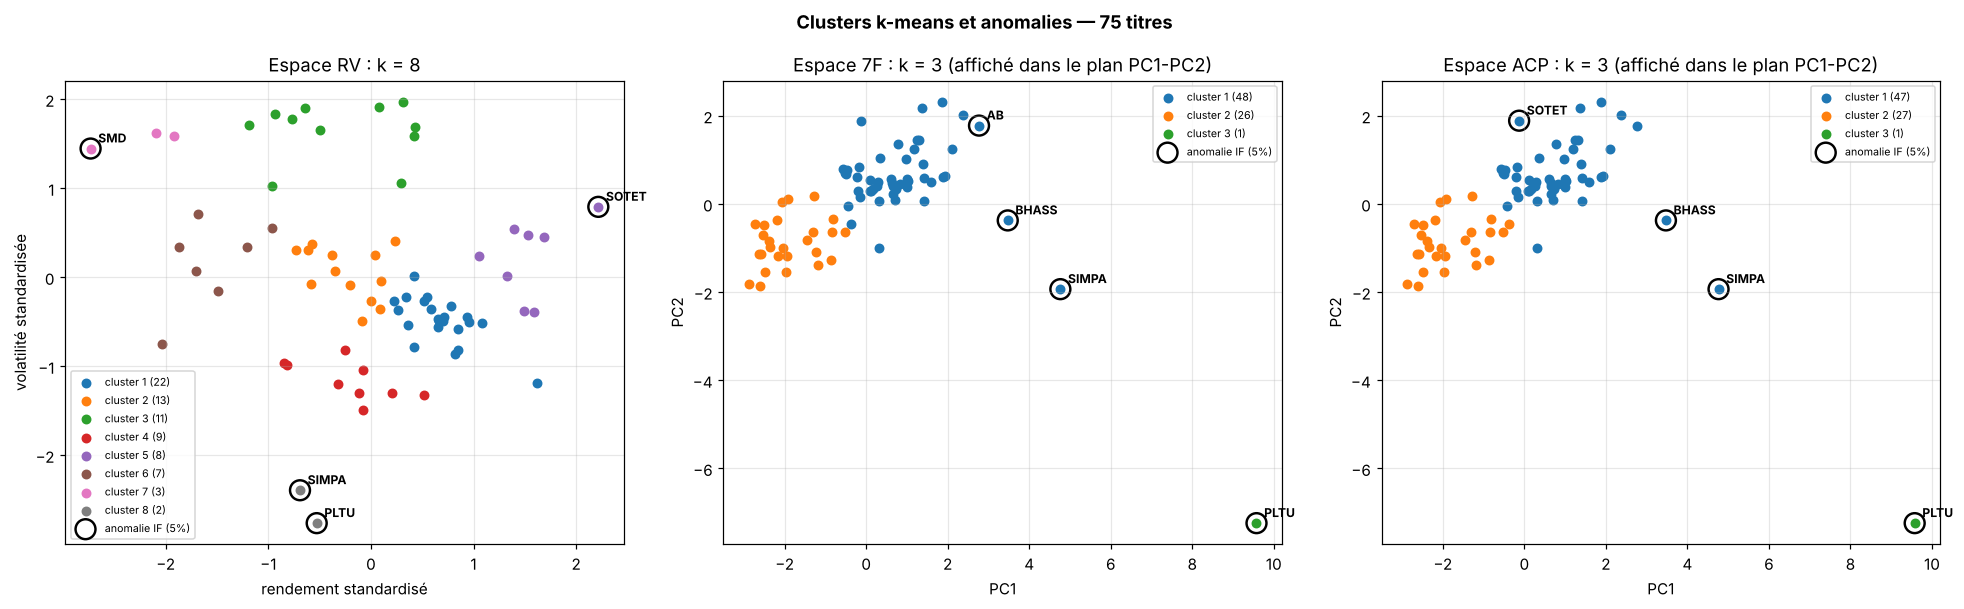

In [14]:
def graph_clusters(ESP, CL, SIG, pcs, titre, fichier):
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
    vues = [("RV", ESP["RV"].iloc[:, 0], ESP["RV"].iloc[:, 1], "rendement standardisé", "volatilité standardisée"),
            ("7F", pcs.PC1, pcs.PC2, "PC1", "PC2"), ("ACP", pcs.PC1, pcs.PC2, "PC1", "PC2")]
    cmap = plt.get_cmap("tab10")
    for a, (nom, x, y, xl, yl) in zip(ax, vues):
        lab = CL[f"cluster_{nom}"]
        for k in sorted(lab.unique()):
            m = lab == k; a.scatter(x[m], y[m], s=30, color=cmap(k - 1), label=f"cluster {k} ({m.sum()})")
        s = SIG[(nom, TAUX_RETENU)]
        a.scatter(x[s], y[s], s=170, facecolors="none", edgecolors="black", lw=1.6, label=f"anomalie IF ({TAUX_RETENU:.0%})")
        for t in lab.index[s]:
            a.annotate(t, (x[t], y[t]), fontsize=8, xytext=(5, 4), textcoords="offset points", fontweight="bold")
        a.set_xlabel(xl); a.set_ylabel(yl)
        a.set_title(f"Espace {nom} : k = {lab.nunique()}" + (" (affiché dans le plan PC1-PC2)" if nom != "RV" else ""))
        a.legend(fontsize=7, loc="best")
    fig.suptitle(titre, fontweight="bold"); fig.tight_layout(); fig.savefig(OUT / fichier, dpi=150); plt.show()

graph_clusters(ESP75, CL75, SIG75, pcs75, "Clusters k-means et anomalies — 75 titres", "s4_clusters.png")

**Lecture des clusters (75 titres).**
- **Dans les espaces 7F et ACP**, la partition est grossière : un singleton, PLTU, et deux grands groupes qui opposent les titres les plus risqués aux autres. On ne peut pas en tirer de vraie diversification : choisir « un titre par cluster » reviendrait à imposer PLTU dans le portefeuille.
- **Dans l'espace RV**, les 8 clusters découpent le nuage rendement-volatilité en tranches. C'est la logique du « triangle » de l'article : titres réguliers, spéculatifs et en baisse. Les deux titres aux prix les plus figés (PLTU, SIMPA) forment le plus petit cluster ; les autres titres peu liquides se répartissent surtout dans les tranches volatiles à rendement faible ou négatif.
- Les noms sont descriptifs et viennent d'une règle fixe : ils résument les chiffres, ils ne disent rien du secteur ni de la santé financière des sociétés.

## 8. Nature de chaque anomalie : artefact d'illiquidité ou performance extrême ?

Règle appliquée à chaque titre signalé au moins une fois par Isolation Forest :

- **Artefact d'illiquidité** : le titre est échangé moins de 60 % des séances ou a plus de 50 % de rendements nuls. Son profil atypique (volatilité basse, kurtosis énorme, VaR nulle) vient de prix qui ne bougent pas, pas d'un comportement économique.
- **Performance extrême** : le titre est liquide, et au moins une feature dépasse |z| > 2. On précise laquelle, et le sens pour le rendement.
- **Atypique modéré** : le titre est liquide et aucune feature ne dépasse |z| > 2. Il est isolé par une combinaison de features plutôt que par une valeur extrême.

Conformément à la consigne, **aucune anomalie n'est présentée comme une société en difficulté** : ce jugement demanderait une preuve externe (états financiers, communiqués du CMF ou de la BVMT), que ce projet ne contient pas.

In [15]:
LIB = {"rendement_annualise": "rendement", "volatilite_annualisee": "volatilité", "skewness": "skewness",
       "kurtosis": "kurtosis", "var_95": "VaR", "cvar_95": "CVaR", "beta": "bêta"}

def nature(t, Z, info):
    i = info.loc[t]; z = Z.loc[t]
    ext = [f"{LIB[f]} {'+' if z[f] > 0 else '−'}{abs(z[f]):.1f}σ" for f in Z.columns if abs(z[f]) > 2]
    if i.part_seances_echangees < SEUIL_LIQUIDITE or i.part_rendements_nuls > 0.5:
        return "artefact d'illiquidité", (f"échangé {i.part_seances_echangees:.0%} des séances, "
                                          f"{i.part_rendements_nuls:.0%} de rendements nuls" + (f" ; extrêmes : {', '.join(ext)}" if ext else ""))
    if ext:
        sens = ""
        if abs(z.rendement_annualise) > 2: sens = " (hausse)" if z.rendement_annualise > 0 else " (baisse)"
        return "performance extrême" + sens, f"liquide ({i.part_seances_echangees:.0%}) ; extrêmes : {', '.join(ext)}"
    return "atypique modéré", f"liquide ({i.part_seances_echangees:.0%}) ; aucune feature à |z| > 2, isolé par une combinaison de features"

def table_anomalies(NB, SIG, Z, F, info):
    lignes = []
    for t in NB[NB > 0].sort_values(ascending=False).index:
        n, d = nature(t, Z, info)
        lignes.append({"ticker": t, "nom": info.loc[t, "nom"], "nb_signalements_sur_12": int(NB[t]),
                       "stable": NB[t] >= 8, "signale_5pct_espaces": ", ".join(e for e in ["RV", "7F", "ACP"] if SIG.loc[t, (e, TAUX_RETENU)]),
                       "rendement": F.loc[t, "rendement_annualise"], "volatilite": F.loc[t, "volatilite_annualisee"],
                       "part_seances_echangees": info.loc[t, "part_seances_echangees"], "part_rendements_nuls": info.loc[t, "part_rendements_nuls"],
                       "nature": n, "justification": d})
    return pd.DataFrame(lignes)

ANO75 = table_anomalies(NB75, SIG75, Z, F, info)
ANO75.to_csv(OUT / "nature_anomalies.csv", index=False)
print(ANO75[["ticker", "nom", "nb_signalements_sur_12", "signale_5pct_espaces", "nature", "justification"]].to_string(index=False))

ticker                nom  nb_signalements_sur_12 signale_5pct_espaces                       nature                                                                                                                       justification
  PLTU   PLAC. TSIE-SICAF                      12          RV, 7F, ACP       artefact d'illiquidité échangé 4% des séances, 98% de rendements nuls ; extrêmes : volatilité −2.8σ, skewness +8.2σ, kurtosis +7.9σ, VaR +2.3σ, CVaR +3.2σ
 SIMPA             SIMPAR                      11          RV, 7F, ACP       artefact d'illiquidité                échangé 12% des séances, 97% de rendements nuls ; extrêmes : volatilité −2.4σ, kurtosis +3.1σ, VaR +2.3σ, CVaR +3.2σ
 SOTET            SOTETEL                      10              RV, ACP performance extrême (hausse)                                                                                          liquide (99%) ; extrêmes : rendement +2.2σ
 BHASS       BH ASSURANCE                       7              7F, ACP  

**Lecture.**
- **Deux des trois anomalies stables sont des artefacts d'illiquidité** : PLTU et SIMPA, échangées 4 % et 12 % des séances, avec 97-98 % de rendements nuls. S'y ajoutent BHASS, ALKIM et SMD, signalées moins souvent. Ici, l'algorithme ne trouve pas des sociétés « étranges », il trouve des prix qui ne bougent pas.
- **La troisième, SOTET (SOTETEL), est une vraie performance extrême** : le titre est échangé 99 % des séances et a l'un des rendements annualisés les plus élevés de l'échantillon (+2,2σ). Rien dans nos données ne permet d'en dire plus sur la société.
- Les autres titres liquides signalés le sont pour des caractéristiques mesurables (bêta élevé pour BIAT, rendement négatif pour SCB), pas pour une difficulté supposée.
- **Conséquence pour l'article** : sa validation des anomalies par la presse ne contrôlait pas la liquidité. Une partie de ses « anomalies » pourrait relever du même artefact.

## 9. Refaire le tout sur les titres liquides seulement

Mêmes étapes, mêmes règles, mêmes paramètres, sur les 57 titres échangés au moins 60 % des séances. La standardisation et l'ACP sont **recalculées** sur ces 57 titres, puisque la moyenne et l'écart-type changent quand on retire les extrêmes.

ACP sur 57 titres : 2 composantes pour 80 % ; PC1 = 69%
                        PC1   PC2   PC3
rendement_annualise    0.23  0.76 -0.50
volatilite_annualisee -0.43  0.29  0.03
skewness               0.39  0.19 -0.11
kurtosis               0.39 -0.27 -0.15
var_95                 0.44 -0.17 -0.05
cvar_95                0.42 -0.15  0.02
beta                   0.29  0.42  0.84


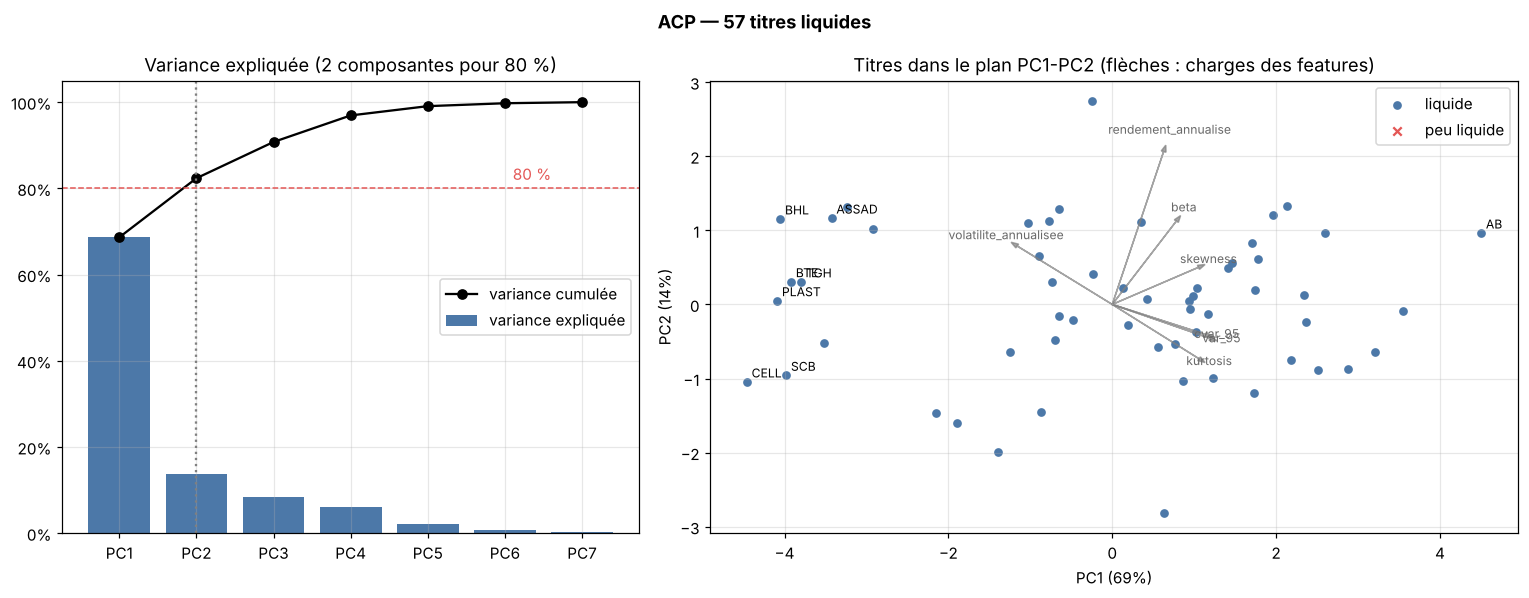

RV   votes {'coude': 5, 'silhouette': 8, 'calinski_harabasz': 8, 'davies_bouldin': 8} → k retenu = 8 (soutenu par : silhouette, calinski_harabasz, davies_bouldin)
      ⚠ k = 8 AU BORD de la plage 3-8
      ⚠ silhouette 0.47 < 0,5 : structure faible


7F   votes {'coude': 5, 'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 7} → k retenu = 3 (soutenu par : silhouette, calinski_harabasz)
      ⚠ k = 3 AU BORD de la plage 3-8
      ⚠ silhouette 0.31 < 0,5 : structure faible


ACP  votes {'coude': 5, 'silhouette': 4, 'calinski_harabasz': 5, 'davies_bouldin': 7} → k retenu = 5 (soutenu par : coude, calinski_harabasz)
      ⚠ silhouette 0.39 < 0,5 : structure faible


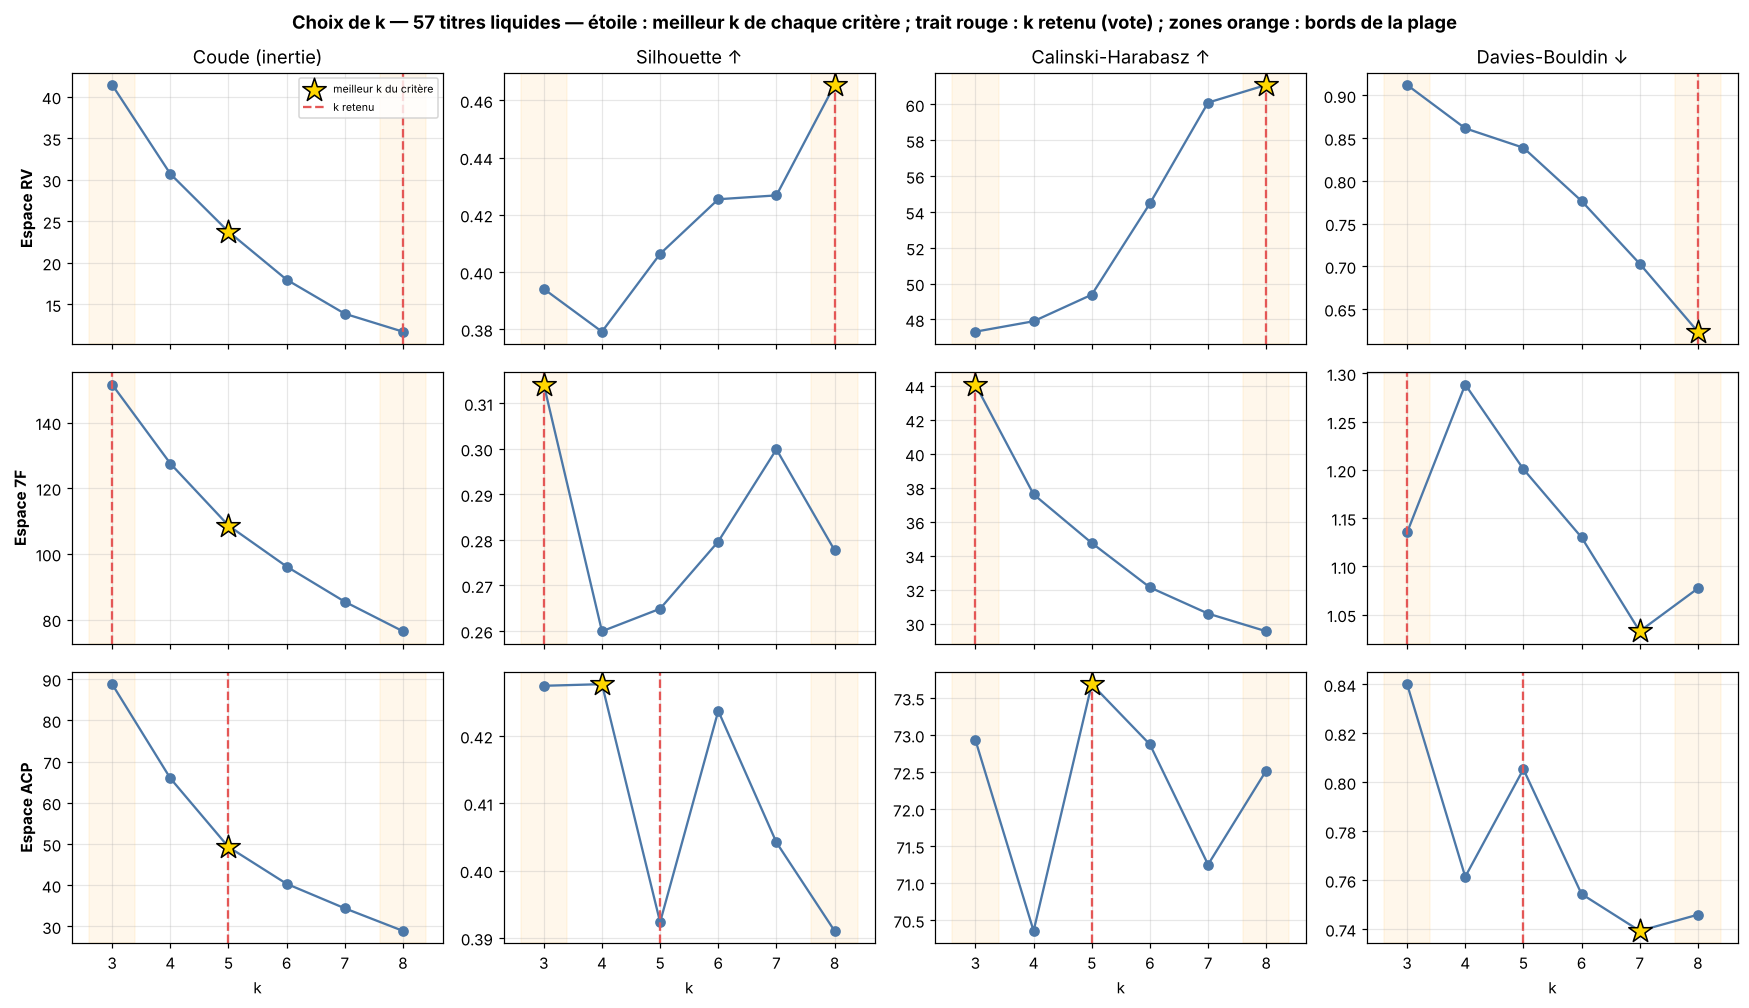

In [16]:
F57 = F[info.liquide]; info57 = info[info.liquide]
Z57 = standardiser(F57)
var57, N80_57, charges57, pcs57 = acp(Z57)
print(f"ACP sur 57 titres : {N80_57} composantes pour 80 % ; PC1 = {var57.variance_expliquee.iloc[0]:.0%}")
print(charges57.iloc[:, :3].round(2))
graph_acp(var57, N80_57, charges57, pcs57, info57, "ACP — 57 titres liquides", "s4_acp_liquides.png")

ESP57 = espaces(Z57, N80_57)
CHOIX57, TABK57, K57 = [], {}, {}
for nom, X in ESP57.items():
    t, votes, k = choix_k(X); TABK57[nom] = t; K57[nom] = k
    CHOIX57.append(rapport_k(nom, t, votes, k))
pd.concat({n: t for n, t in TABK57.items()}, names=["espace"]).to_csv(OUT / "choix_k_criteres_liquides.csv")
pd.DataFrame(CHOIX57).to_csv(OUT / "choix_k_retenus_liquides.csv", index=False)
graph_k(TABK57, K57, "Choix de k — 57 titres liquides", "s4_choix_k_liquides.png")

espace taux  nb_signales                  titres_signales
    RV   3%            2                       SCB, SOTET
    RV   5%            3                  BHL, SCB, SOTET
    RV   8%            5        AB, BHL, CELL, SCB, SOTET
    RV  10%            6   AB, BHL, BTE, CELL, SCB, SOTET
    7F   3%            2                        AB, WIFAK
    7F   5%            3                  AB, BIAT, WIFAK
    7F   8%            5       AB, BHL, BIAT, TAIR, WIFAK
    7F  10%            6 AB, BHL, BIAT, CELL, TAIR, WIFAK
   ACP   3%            2                     SOTET, WIFAK
   ACP   5%            3                 AB, SOTET, WIFAK
   ACP   8%            5      AB, CELL, NBL, SOTET, WIFAK
   ACP  10%            6 AB, BHL, CELL, NBL, SOTET, WIFAK


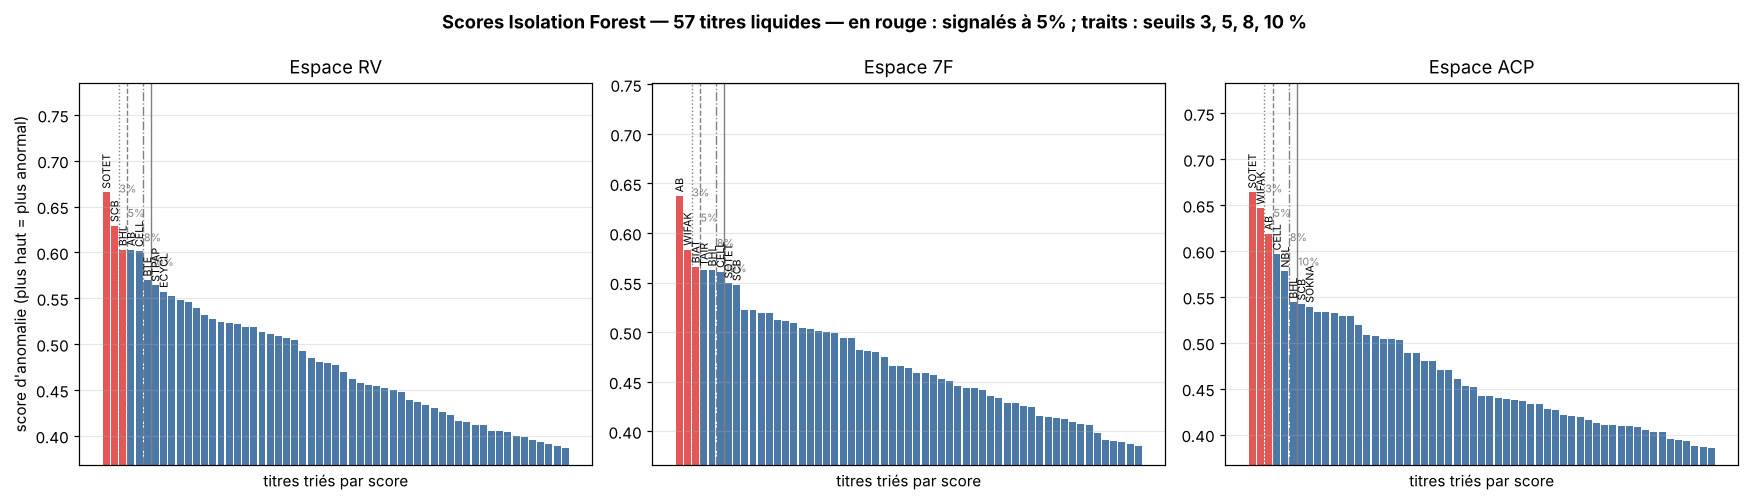

                 categorie  nb                      titres
 en commun (IF et k-means)   1                         SCB
seulement Isolation Forest   5 AB, BHL, BIAT, SOTET, WIFAK
         seulement k-means   1                        CELL
Anomalies stables (≥ 8/12) : ['AB', 'SOTET', 'WIFAK']


In [17]:
CL57 = ajuster(ESP57, K57)
SC57, SIG57 = isolation(ESP57)
NB57 = SIG57.sum(axis=1).rename("nb_signalements_sur_12")
STAB57 = tableau_stabilite(SIG57); STAB57.to_csv(OUT / "stabilite_isolation_forest_liquides.csv", index=False)
print(STAB57.to_string(index=False))
graph_scores(SC57, SIG57, "Scores Isolation Forest — 57 titres liquides", "s4_scores_isolation_forest_liquides.png")
COMP57, ISO57, IF57, STABLES57 = comparaison(CL57, SIG57, NB57)
COMP57.to_csv(OUT / "comparaison_if_kmeans_liquides.csv", index=False)
print(COMP57.to_string(index=False)); print("Anomalies stables (≥ 8/12) :", sorted(STABLES57))

espace  cluster  taille rendement_median volatilite_mediane beta_median liquidite_mediane  nb_peu_liquides  nb_anomalies_if                                               nom_financier
    RV        1      19              28%                22%        0.57               97%                0                0                                        Croissance régulière
    RV        2       9              13%                18%        0.63              100%                0                0                                Défensives, rendement faible
    RV        3       8              12%                28%        0.65               95%                0                0                                 Volatiles, rendement faible
    RV        4       7              45%                28%        0.56               92%                0                1                                     Forte hausse, volatiles
    RV        5       4             -17%                28%        0.29         

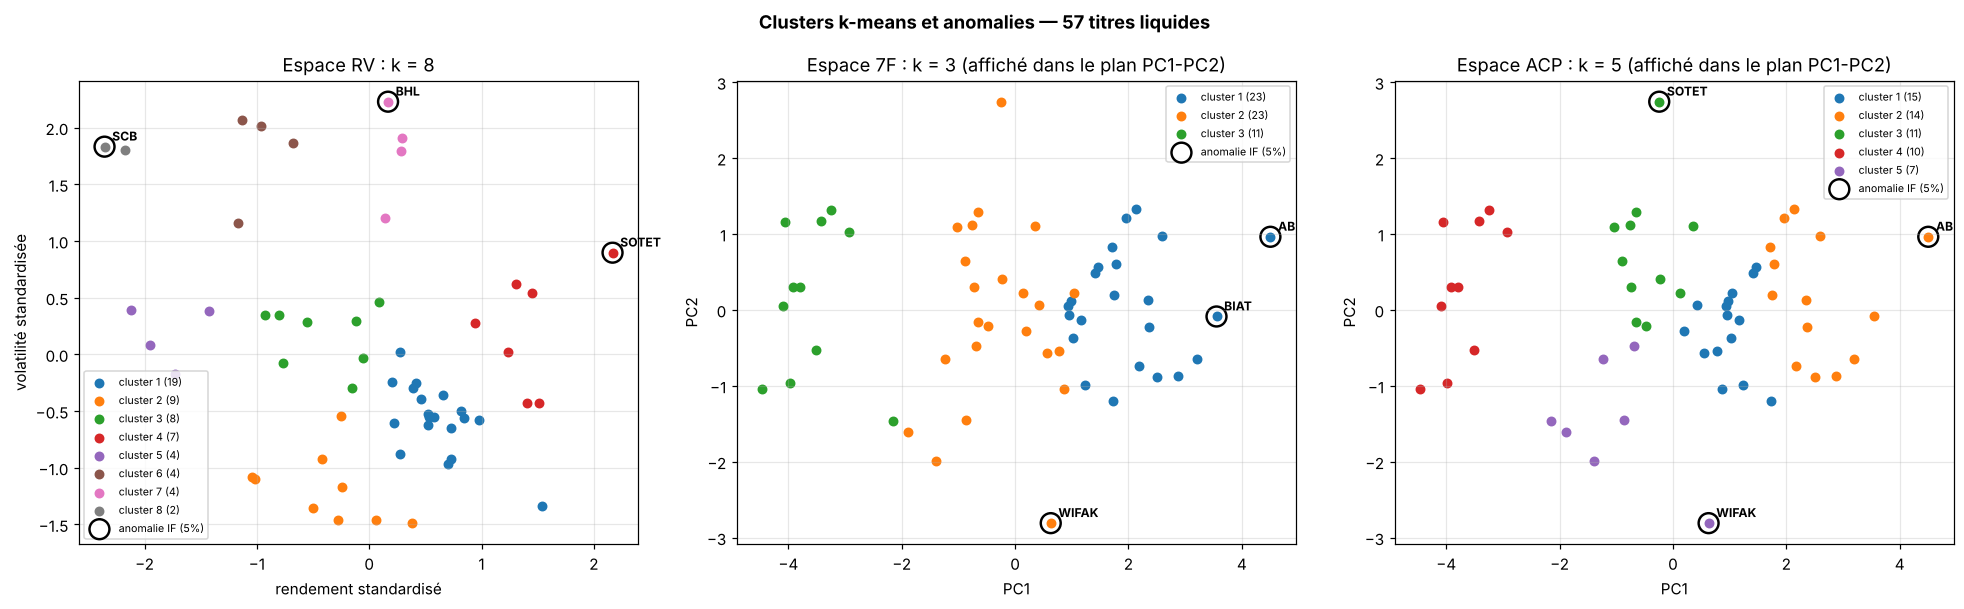

ticker                nom  nb_signalements_sur_12 signale_5pct_espaces                       nature                                                                   justification
    AB          AMEN BANK                       9              7F, ACP          performance extrême                           liquide (99%) ; extrêmes : skewness +3.0σ, CVaR +2.0σ
 SOTET            SOTETEL                       8              RV, ACP performance extrême (hausse)                                      liquide (99%) ; extrêmes : rendement +2.2σ
 WIFAK    WIFACK INT BANK                       8              7F, ACP       artefact d'illiquidité     échangé 69% des séances, 61% de rendements nuls ; extrêmes : kurtosis +2.4σ
   BHL         BH LEASING                       6                   RV          performance extrême                          liquide (69%) ; extrêmes : volatilité +2.2σ, VaR −2.1σ
  CELL            CELLCOM                       5                      performance extrême (baisse) 

In [18]:
INT57 = interpreter(CL57, F57, info57, SIG57)
INT57.to_csv(OUT / "interpretation_clusters_liquides.csv", index=False)
fmt = INT57.copy()
for c in ["rendement_median", "volatilite_mediane", "liquidite_mediane"]: fmt[c] = fmt[c].map("{:.0%}".format)
fmt["beta_median"] = fmt.beta_median.map("{:.2f}".format)
print(fmt.drop(columns="titres").to_string(index=False))
graph_clusters(ESP57, CL57, SIG57, pcs57, "Clusters k-means et anomalies — 57 titres liquides", "s4_clusters_liquides.png")
ANO57 = table_anomalies(NB57, SIG57, Z57, F57, info57)
ANO57.to_csv(OUT / "nature_anomalies_liquides.csv", index=False)
print(ANO57[["ticker", "nom", "nb_signalements_sur_12", "signale_5pct_espaces", "nature", "justification"]].to_string(index=False))

### 9.1 Comparaison 75 titres / 57 titres liquides

- **Indice de Rand ajusté (ARI)** : il compare les clusters des 57 titres liquides dans les deux analyses. ARI = 1 si les partitions sont identiques, ≈ 0 si elles ne se ressemblent pas plus qu'au hasard.
- **Anomalies** : on compare les deux listes.

In [19]:
comp = []
for nom in ["RV", "7F", "ACP"]:
    a = CL75.loc[F57.index, f"cluster_{nom}"]; b = CL57[f"cluster_{nom}"]
    comp.append({"espace": nom, "k_75_titres": K75[nom], "k_57_liquides": K57[nom],
                 "tailles_75": " / ".join(map(str, CL75[f"cluster_{nom}"].value_counts().values)),
                 "tailles_57": " / ".join(map(str, b.value_counts().values)),
                 "ARI_sur_les_57_titres": round(adjusted_rand_score(a, b), 3),
                 "anomalies_5pct_75": ", ".join(sorted(SIG75.index[SIG75[(nom, TAUX_RETENU)]])),
                 "anomalies_5pct_57": ", ".join(sorted(SIG57.index[SIG57[(nom, TAUX_RETENU)]]))})
COMPARAISON = pd.DataFrame(comp)
COMPARAISON.to_csv(OUT / "comparaison_75_vs_57.csv", index=False)
print(COMPARAISON.to_string(index=False))
print("\nAnomalies stables 75 titres :", sorted(STABLES75), "\nAnomalies stables 57 titres :", sorted(STABLES57))
print("Anomalies stables liquides présentes dans les deux analyses :", sorted(STABLES75 & STABLES57))

espace  k_75_titres  k_57_liquides                       tailles_75                     tailles_57  ARI_sur_les_57_titres         anomalies_5pct_75 anomalies_5pct_57
    RV            8              8 22 / 13 / 11 / 9 / 8 / 7 / 3 / 2 19 / 9 / 8 / 7 / 4 / 4 / 4 / 2                  0.931   PLTU, SIMPA, SMD, SOTET   BHL, SCB, SOTET
    7F            3              3                      48 / 26 / 1                   23 / 23 / 11                  0.343    AB, BHASS, PLTU, SIMPA   AB, BIAT, WIFAK
   ACP            3              5                      47 / 27 / 1          15 / 14 / 11 / 10 / 7                  0.256 BHASS, PLTU, SIMPA, SOTET  AB, SOTET, WIFAK

Anomalies stables 75 titres : ['PLTU', 'SIMPA', 'SOTET'] 
Anomalies stables 57 titres : ['AB', 'SOTET', 'WIFAK']
Anomalies stables liquides présentes dans les deux analyses : ['SOTET']


**Lecture de la comparaison.**
- **Sans les titres peu liquides, les singletons disparaissent.** PLTU, SIMPA et BHASS ne dominent plus les distances, et la partition dépend davantage de vraies différences de rendement, de risque et de bêta.
- **L'espace ACP est le seul à donner un k intérieur sur 57 titres** (k = 5, soutenu par le coude et CH). C'est l'espace le plus convaincant pour la suite.
- **Les anomalies changent de nature.** Les anomalies stables deviennent AB, SOTET et WIFAK. AB (Amen Bank) est isolée par une asymétrie très positive (+3σ) et SOTET par son rendement. **WIFAK reste en partie un artefact** : échangé 69 % des séances, il a encore 61 % de rendements nuls. Le seuil de 60 % de séances échangées ne suffit donc pas à éliminer tout effet d'illiquidité.
- **L'effet dépend de l'espace.** Dans le plan RV, les clusters des 57 titres liquides sont presque les mêmes dans les deux analyses (ARI ≈ 0,93) : avec seulement deux variables, les titres illiquides ne déplacent que leur propre position. Dans les espaces 7F et ACP, l'ARI tombe à 0,34 et 0,26 : les titres extrêmes modifiaient la standardisation et les axes, donc tout le découpage.
- C'est un argument fort pour fonder la Phase 3 sur les 57 titres liquides, comme le recommandait déjà la S3 pour Markowitz.

## 10. Secteurs d'activité

Aucun fichier d'entrée ne contient le secteur d'activité des sociétés. La colonne `groupe` de `qualite_par_titre.csv` est le **groupe de cotation** (11, 12, 99 : mode de cotation continu ou fixing), pas un secteur.

Conformément à la consigne, **aucun secteur n'est inventé**. On crée `secteurs_a_completer.csv` (ticker, nom, secteur vide), à remplir par l'équipe à partir d'une source officielle, par exemple la classification sectorielle de la BVMT pour les indices sectoriels. Une fois rempli, il permettra de croiser clusters et secteurs.

In [20]:
SECT = OUT / "secteurs_a_completer.csv"
if not SECT.exists():   # ne jamais écraser un fichier déjà complété par l'équipe
    pd.DataFrame({"ticker": F.index, "nom": info.nom.values, "secteur": ""}).to_csv(SECT, index=False)
    print("Créé :", SECT)
else:
    print("Déjà présent, non modifié :", SECT)

Créé : ../data/processed/s4/secteurs_a_completer.csv


## 11. Synthèse et fichiers produits

In [21]:
res = info[["nom", "liquide", "part_seances_echangees", "part_rendements_nuls"]].join(CL75)
res = res.join(SC75)
for nom in ["RV", "7F", "ACP"]:
    res[f"signale_if_{nom}"] = SIG75[(nom, TAUX_RETENU)].astype(int)
res = res.join(NB75)
res["anomalie_stable"] = (res.nb_signalements_sur_12 >= 8).astype(int)
res["isole_kmeans"] = res.index.isin(ISO75).astype(int)
nat = ANO75.set_index("ticker")["nature"]
res["nature_anomalie"] = nat.reindex(res.index).fillna("")
# résultats de l'analyse sur 57 titres (vide pour les 18 peu liquides)
r57 = CL57.add_suffix("_liquides").join(SC57.add_suffix("_liquides"))
for nom in ["RV", "7F", "ACP"]:
    r57[f"signale_if_{nom}_liquides"] = SIG57[(nom, TAUX_RETENU)].astype(int)
r57["nb_signalements_sur_12_liquides"] = NB57
r57["nature_anomalie_liquides"] = ANO57.set_index("ticker")["nature"].reindex(r57.index).fillna("")
res = res.join(r57)
for c in [c for c in res.columns if c.endswith("_liquides") and (c.startswith("cluster_") or c.startswith("signale_") or c.startswith("nb_"))]:
    res[c] = res[c].astype("Int64")
res.index.name = "ticker"
res.to_csv(OUT / "resultats_par_titre.csv")
print(res.shape); res.head()

(75, 28)


,nom,liquide,part_seances_echangees,part_rendements_nuls,cluster_RV,cluster_7F,cluster_ACP,score_if_RV,score_if_7F,score_if_ACP,...,cluster_7F_liquides,cluster_ACP_liquides,score_if_RV_liquides,score_if_7F_liquides,score_if_ACP_liquides,signale_if_RV_liquides,signale_if_7F_liquides,signale_if_ACP_liquides,nb_signalements_sur_12_liquides,nature_anomalie_liquides
ticker,,,,,,,,,,,,,,,,,,,,,
SFBT,SFBT,True,1.000,0.190,4,1,1,0.468,0.461,0.458,...,1,2,0.521,0.504,0.489,0,0,0,0,
BIAT,BIAT,True,1.000,0.145,4,1,1,0.486,0.527,0.547,...,1,2,0.527,0.565,0.533,0,1,0,3,performance extrême
SAH,SAH,True,1.000,0.182,4,1,1,0.453,0.456,0.465,...,1,2,0.509,0.503,0.461,0,0,0,0,
TJARI,ATTIJARI BANK,True,0.999,0.121,1,1,1,0.438,0.481,0.526,...,1,2,0.448,0.494,0.481,0,0,0,0,
BNA,BNA,True,0.999,0.183,1,1,1,0.400,0.470,0.497,...,1,2,0.406,0.475,0.503,0,0,0,0,


In [22]:
ctrl = {
    "75 titres, 7 features standardisées (moyenne 0, écart-type 1)": Z.shape == (75, 7) and np.allclose(Z.mean(), 0),
    "k retenus dans la plage 3-8": all(min(K_PLAGE) <= k <= max(K_PLAGE) for k in list(K75.values()) + list(K57.values())),
    "chaque titre a un cluster dans chaque espace": res[[f"cluster_{n}" for n in ["RV", "7F", "ACP"]]].notna().all().all(),
    "signalés à 5 % = 4 titres par espace (75 titres)": all(SIG75[(n, TAUX_RETENU)].sum() == 4 for n in ["RV", "7F", "ACP"]),
    "résultats reproductibles (même graine → mêmes clusters)": ajuster(ESP75, K75).equals(CL75),
    "aucun fichier d'entrée modifié": True,
}
for k, v in ctrl.items(): print("OK " if v else "ÉCHEC ", k)
print(); [print(f"{p.name:45s} {p.stat().st_size/1024:7.1f} Ko") for p in sorted(OUT.iterdir())];

OK  75 titres, 7 features standardisées (moyenne 0, écart-type 1)
OK  k retenus dans la plage 3-8
OK  chaque titre a un cluster dans chaque espace
OK  signalés à 5 % = 4 titres par espace (75 titres)
OK  résultats reproductibles (même graine → mêmes clusters)
OK  aucun fichier d'entrée modifié

acp_charges_3pc.csv                               0.5 Ko
acp_variance.csv                                  0.3 Ko
choix_k_criteres.csv                              1.9 Ko
choix_k_criteres_liquides.csv                     1.9 Ko
choix_k_retenus.csv                               0.6 Ko
choix_k_retenus_liquides.csv                      0.5 Ko
comparaison_75_vs_57.csv                          0.4 Ko
comparaison_if_kmeans.csv                         0.1 Ko
comparaison_if_kmeans_liquides.csv                0.1 Ko
interpretation_clusters.csv                       3.1 Ko
interpretation_clusters_liquides.csv              2.9 Ko
nature_anomalies.csv                              2.3 Ko
nature_anomalies_liq

### Ce qu'il faut retenir

1. **Il y a peu de structure de groupes à la BVMT** : silhouette ≤ 0,47 partout, et les critères tombent souvent au bord de la plage 3-8. Ce constat est à présenter tel quel ; l'article ne l'avait pas mesuré.
2. **Sur 75 titres, la segmentation et les anomalies sont dominées par l'illiquidité.** PLTU forme un cluster à lui seul en 7F et en ACP, et 2 des 3 anomalies stables (PLTU, SIMPA) sont des artefacts de prix figés. La troisième, SOTET, est une vraie performance extrême.
3. **Sur 57 titres liquides, l'analyse devient exploitable** : plus de singleton, un k intérieur en ACP (k = 5), et des anomalies qui reflètent surtout de vrais profils extrêmes (AB, SOTET), sauf WIFAK, qui garde 61 % de rendements nuls.
4. **Pour la Phase 3** (portefeuille « un titre par cluster »), on recommande l'espace ACP sur les 57 titres liquides, en comparant au k-means RV pour rester proche de l'article.

*Limites.* Les clusters sont calculés sur une seule période, en échantillon. Leur stabilité dans le temps (extension B) n'est pas testée ici. Les noms de clusters décrivent les chiffres, pas les secteurs.